<a href="https://colab.research.google.com/github/katheleya/-sort-names-cpp/blob/main/TMI4013_A2_G11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TMI4013 DATA MINING
# Assignment 2: Predictive Modeling and Model Evaluation

# Group 11:

1. Claudia Anak Grunsin (98540)

2. Faridah Binti Samsuar (98921)

3. Katheleye Nolla Anak Akau (99383)

4. Samantha Christie Anak Lubong (100927)



## Dataset Desciption

This assignment uses the Stroke Prediction Dataset from Kaggle.

The dataset contains patient-related information, such as age, hypertension, heart disease, glucose level, BMI and smoking status.

The target variable is 'stroke', where:

- 0 represents no stroke

- 1 represents stroke

The dataset was cleaned and preprocessed in Assignment 1.

The file used for this assignment is 'cleaned_dataset_from_A1.csv'.

URL for dataset source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

Below is the Google Drive Link to access the folder containing the datasets used in this Assignment 2:
https://drive.google.com/drive/folders/1ECGOMbCIJ4Dfo_HQhzxZHvPdn5XxRJqL?usp=drive_link

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from IPython.display import display

RANDOM_STATE = 42

# Task 1: Data Splitting


In [ ]:
df = pd.read_csv("/cleaned_dataset_from_A1.csv")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
display(df[['age', 'avg_glucose_level', 'bmi']].describe().round(2))   # check if already scaled
print(df['stroke'].value_counts(normalize=True).round(3))

# Drop columns with no predictive value
df = df.drop(columns=['id', 'gender_Other'])

# Features and target
X = df.drop(columns='stroke')
y = df['stroke']

# 80/20 split, stratified because stroke is only ~5% of the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTrain:", X_train.shape, "| Test:", X_test.shape)
print("Stroke rate (train):", round(y_train.mean(), 3))
print("Stroke rate (test): ", round(y_test.mean(), 3))

Shape: (5110, 18)
Missing values: 0


,age,avg_glucose_level,bmi
count,5110.00,5110.00,5110.00
mean,43.23,4.60,3.37
std,22.61,0.36,0.25
min,0.08,4.03,2.42
25%,25.00,4.36,3.21
50%,45.00,4.53,3.37
75%,61.00,4.75,3.52
max,82.00,5.61,4.59


stroke
0    0.951
1    0.049
Name: proportion, dtype: float64

Train: (4088, 15) | Test: (1022, 15)
Stroke rate (train): 0.049
Stroke rate (test):  0.049


In [ ]:
df.to_csv('dataset_after_task1.csv', index=False)

print("Dataset after Task 1 saved successfully.")

Dataset after Task 1 saved successfully.


**DESCRIPTION:**

The data was split 80/20 (4088 training, 1022 testing). random_state=42 makes the split reproducible. stratify=y keeps the same proportion of stroke cases (about 4.9%) in both sets, since the dataset is heavily imbalanced. id and gender_Other were removed because id is only an identifier and gender_Other has just 1 record. The testing set is not used until final evaluation.

# Task 2: Modeling

### Model A (Person A)

### 2.1 Decision Tree Classifier

A Decision Tree splits the data into smaller groups by asking a series of yes/no questions about the features (e.g. "is age > 60?"), choosing the split that best separates stroke from non-stroke cases at each step. It is easy to interpret and does not need feature scalin, but a deep tree can overfit the training data. class_weight='balanced' is used because only about 5% of patients had a stroke, so the model gives more weight to the minority class.

In [ ]:
dt_base = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=RANDOM_STATE
)
dt_base.fit(X_train, y_train)

print("Baseline Decision Tree trained")
print("Tree depth:", dt_base.get_depth())
print("Number of leaves:", dt_base.get_n_leaves())

Baseline Decision Tree trained
Tree depth: 23
Number of leaves: 391


### Model B (Person B)

### 2.2 Logistic Regress


Logistic Regression is a supervised machine learning algorithm that calculates a weighted sum of the input features and applies the sigmoid funtion to convert it into a probability between 0 and 1. If the probability exceeds a threshold (in this case is 0.5), the input is classified into the positive class. In this assignment, Logistic Regression is used to predict whether a person has experienced a stroke (stroke = 1) or not ( stroke = 0).

In [ ]:
numeric_cols = ['age', 'avg_glucose_level', 'bmi']

def build_lr(**params):
    preprocessor = ColumnTransformer(
        [('scale', StandardScaler(), numeric_cols)],
        remainder='passthrough'
    )
    return Pipeline([
        ('preprocess', preprocessor),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **params))
    ])

lr_base = build_lr()
lr_base.fit(X_train, y_train)

print("Baseline Logistic Regression trained")


Baseline Logistic Regression trained


### Model C (Person C)

### 2.3 Random Forest Classifier

Random Forest is a supervised machine learning algorithm that combines multiple decision trees to make predictions. Each tree produces a prediction, and the model combines these predictions to determine the final classification. In this assignment, Random Forest is used to predict whether a person has experienced a stroke (stroke = 1) or has not experienced a stroke (stroke = 0).

In [ ]:
# Train the Random Forest model

rf_base = RandomForestClassifier(
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_base.fit(X_train, y_train)

print("Random Forest model trained successfully.")
print("Number of trees:", len(rf_base.estimators_))
print("Maximum depth:", rf_base.max_depth)

Random Forest model trained successfully.
Number of trees: 100
Maximum depth: None


# Task 3: Hyperparameter Tuning

In [ ]:
### Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

### Model A

In [ ]:
dt_param_grid = {
    'max_depth': [3, 4, 5, 6, 8, 10, None],
    'min_samples_split': [2, 10, 20, 50],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(
        class_weight='balanced',
        random_state=RANDOM_STATE
    ),
    param_grid=dt_param_grid,
    scoring='f1',          # F1 on the stroke class, since accuracy is misleading here
    cv=cv,
    n_jobs=-1
)
dt_grid.fit(X_train, y_train)

best_dt = dt_grid.best_estimator_

print("Best parameters:", dt_grid.best_params_)
print("Best CV F1-score:", round(dt_grid.best_score_, 4))
print("Tuned tree depth:", best_dt.get_depth())

Best parameters: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 20}
Best CV F1-score: 0.2226
Tuned tree depth: 10


**JUSTIFICATION**

For the Decision Tree, we used GridSearchCV with 5-fold stratified cross-validation to find the best settings. We tested four hyperparameters: `max_depth` (3, 4, 5, 6, 8, 10 and None), `min_samples_split` (2, 10, 20 and 50), `min_samples_leaf` (1, 5, 10 and 20), and `criterion` (gini and entropy). That is 224 combinations in total, and each one was tested on the training data only, so the test set stayed untouched. We also kept `class_weight='balanced'` because only about 4.9% of the patients had a stroke.

We chose F1-score to pick the best model instead of accuracy. Since most patients (about 95%) did not have a stroke, a model that simply predicts "no stroke" for everyone would still get around 95% accuracy while missing every real case. F1-score is better here because it looks at both precision and recall for the stroke class.

Before tuning, the baseline tree grew to a depth of 23 with 391 leaves. This means it was very complex and likely memorised the training data (overfitting). After tuning, the best settings were `criterion='gini'`, `max_depth=10`, `min_samples_leaf=1` and `min_samples_split=20`, with a best cross-validation F1-score of 0.2226. Limiting the depth and requiring at least 20 samples before a split makes the tree simpler, so it should generalise better to new patients.

The F1-score is still quite low, but this is expected because stroke cases are rare and look similar to non-stroke cases in this dataset. The tuned tree is saved as `best_dt` and will be evaluated on the test set in Task 4.

### Logistic Regression
Hyperparameters are settings chosen before training that control how a model learns, unlike parameters (such as the coefficients), which are learned from the data. For Logistic Regression, we tuned C (the inverse of the regularisation strength), solver (the optimisation algorithm) and class_weight (the weight given to each class during training).

In [ ]:
lr_param_grid = {
    'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'clf__solver': ['lbfgs', 'liblinear'],
    'clf__class_weight': [None, 'balanced']
}

lr_grid = GridSearchCV(
    estimator=build_lr(),
    param_grid=lr_param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)
lr_grid.fit(X_train, y_train)

best_lr = lr_grid.best_estimator_

print("Best parameters:", lr_grid.best_params_)
print("Best CV F1-score:", round(lr_grid.best_score_, 4))

Best parameters: {'clf__C': 10, 'clf__class_weight': 'balanced', 'clf__solver': 'lbfgs'}
Best CV F1-score: 0.229


# Justification
For Logistic Regression, we used GridSearchCV with 5-fold stratified cross-validation on the training data only. We tested C (0.001, 0.01, 0.1, 1, 10 and 100), solver (lbfgs and liblinear) and class_weight (None and balanced), which gives 24 combinations. C is the inverse of the regularisation strength, so smaller values apply stronger regularisation. class_weight='balanced' gives the rare stroke class a larger weight so the model does not simply predict “no stroke” for everyone. F1-score was used for selection instead of accuracy, because about 95% of patients did not have a stroke.

The best combination was C=10, solver='lbfgs' and class_weight='balanced', with a best cross-validation F1-score of 0.229. Every top-ranked combination used class_weight='balanced', so handling the class imbalance mattered much more than the choice of C or solver. The tuned model is saved as best_lr and will be evaluated on the test set in Task 4.

### Random Forest Classifier

Hyperparameter tuning is performed to identify suitable settings for the Random Forest classifier. GridSearchCV evaluates different combinations of hyperparameters using 5-fold stratified cross-validation. The F1-score is used as the scoring metric because the stroke dataset is imbalanced. The best combination is selected based on its average cross-validation F1-score.

In [ ]:
# Random Forest hyperparameter grid

rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5],
    'criterion': ['gini', 'entropy']
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=1
    ),
    param_grid=rf_param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_

print("Best parameters:", rf_grid.best_params_)
print("Best CV F1-score:", round(rf_grid.best_score_, 4))
print("Number of trees:", len(best_rf.estimators_))
print("Maximum depth:", best_rf.max_depth)

Best parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 20, 'n_estimators': 100}
Best CV F1-score: 0.2675
Number of trees: 100
Maximum depth: None


**Justification:**

The hyperparameters tested included `n_estimators` (100 and 200), `max_depth` (None and 10), `min_samples_split` (2,10, and 20),` min_samples_leaf` (1 and 5), and `criterion` (Gini and entropy). The `class_weight`= `balanced` setting was applied to help address the class imbalance in the stroke dataset.

The F1-score was selected as the scoring metric because only approximately 4.9% of the records belong to the stroke class. This metric considers both precision and recall, making it more informative than accuracy alone for an imbalanced classification problem.

The best hyperparameter combination obtained was `criterion = gini` , `max_depth = None`, `min_samples_leaf = 5`, `min_samples_split = 20`, and `n_estimators = 100`. This configuration achieved a best cross-validation F1-score of 0.2675.

The result indicate that this configuration performed best among the combinations tested in terms of average cross-validation F1-score. The selected model, stored as `best_rf`, will be evaluated on the separate test dataset in Task 4 to assess its predictive performance on unseen data.

# Task 4: Evaluation

The tuned models are evaluated using the same testing set.

The following metrics are used:
- Confusion Matrix: Summarises correct and incorrect predictions.
- Accuracy: Measures the proportion of correct predictions.
- Precision: Measures how many predicted stroke cases are actual stroke cases.
- Recall: Measures how many actual stroke cases are correctly identified.
- F1-score: Balances precision and recall.

Since stroke is the positive class, recall and F1-score are also
important when comparing the models.

In [ ]:

# Predict using the tuned models
dt_predictions = best_dt.predict(X_test)
rf_predictions = best_rf.predict(X_test)
lr_predictions = best_lr.predict(X_test)

# Store models and predictions for evaluation
models = {
    'Decision Tree': (best_dt, dt_predictions),
    'Random Forest': (best_rf, rf_predictions),
    'Logistic Regression': (best_lr, lr_predictions)
}

results = []

# for loop used to evaluate all three models, so that we dont have to run the same code multiple times
for name, (model, predictions) in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, zero_division=0
        ),
        'F1-score': f1_score(
            y_test, predictions, zero_division=0
        )
    })

    print(f"\n{name}")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Stroke (0)', 'Stroke (1)']
    ).plot()

    plt.title(f'{name} - Confusion Matrix')
    plt.show()

results_df = pd.DataFrame(results)
display(results_df.round(4))


# Evaluation Model A

Decision Tree (tuned)
              precision    recall  f1-score   support

           0       0.97      0.83      0.89       972
           1       0.13      0.50      0.21        50

    accuracy                           0.81      1022
   macro avg       0.55      0.66      0.55      1022
weighted avg       0.93      0.81      0.86      1022



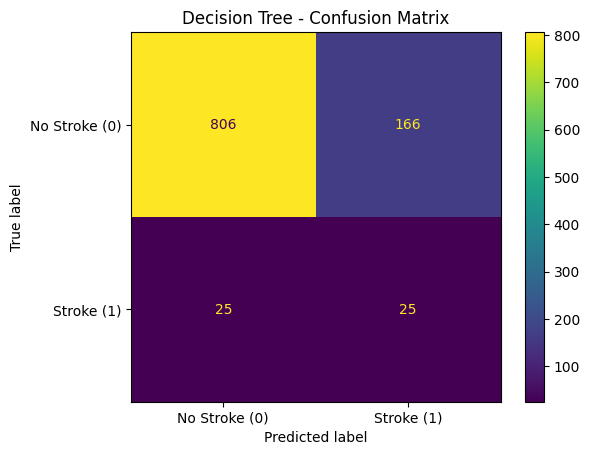

TN=806, FP=166, FN=25, TP=25
Baseline DT: acc=0.931, prec=0.182, recall=0.120, f1=0.145
Tuned DT: acc=0.813, prec=0.131, recall=0.500, f1=0.207


In [ ]:
dt_predictions = best_dt.predict(X_test)

print("Decision Tree (tuned)")
print(classification_report(y_test, dt_predictions, zero_division=0))

cm = confusion_matrix(y_test, dt_predictions)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Stroke (0)', 'Stroke (1)']
).plot()
plt.title('Decision Tree - Confusion Matrix')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

# Optional: baseline vs tuned, to show tuning helped
for name, m in [('Baseline DT', dt_base), ('Tuned DT', best_dt)]:
    p = m.predict(X_test)
    print(f"{name}: acc={accuracy_score(y_test, p):.3f}, "
          f"prec={precision_score(y_test, p, zero_division=0):.3f}, "
          f"recall={recall_score(y_test, p, zero_division=0):.3f}, "
          f"f1={f1_score(y_test, p, zero_division=0):.3f}")

# Evaluation Model B: Logical Regression

Logistic Regression (tuned)
              precision    recall  f1-score   support

           0       0.99      0.75      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



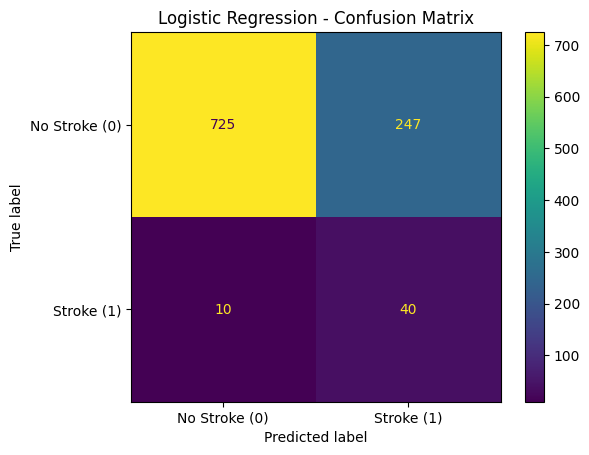

TN=725, FP=247, FN=10, TP=40
Baseline LR: acc=0.952, prec=1.000, recall=0.020, f1=0.039
Tuned LR: acc=0.749, prec=0.139, recall=0.800, f1=0.237


In [ ]:
# Evaluation Model B: Logistic Regression
lr_predictions = best_lr.predict(X_test)

print("Logistic Regression (tuned)")
print(classification_report(y_test, lr_predictions, zero_division=0))

cm = confusion_matrix(y_test, lr_predictions)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Stroke (0)', 'Stroke (1)']
).plot()
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

# Baseline vs tuned
for name, m in [('Baseline LR', lr_base), ('Tuned LR', best_lr)]:
    p = m.predict(X_test)
    print(f"{name}: acc={accuracy_score(y_test, p):.3f}, "
          f"prec={precision_score(y_test, p, zero_division=0):.3f}, "
          f"recall={recall_score(y_test, p, zero_division=0):.3f}, "
          f"f1={f1_score(y_test, p, zero_division=0):.3f}")

# Justification
The tuned Logistic Regression was evaluated on the test set of 1022 records. It achieved an accuracy of 0.7485, a precision of 0.1394, a recall of 0.8000 and an F1-score of 0.2374. The confusion matrix showed 725 true negatives, 247 false positives, 10 false negatives and 40 true positives. Of the 50 actual stroke cases, the model correctly identified 40.

The untuned baseline reached an accuracy of 0.9521, but this was misleading: it predicted almost every patient as “no stroke” and detected only 1 of the 50 strokes (recall 0.02). Tuning with class_weight='balanced' lowered accuracy but raised recall from 0.02 to 0.80, which is why the F1-score improved from 0.04 to 0.24.

The trade-off is a low precision of 0.14, meaning many patients flagged as stroke cases are actually healthy. In stroke screening, missing a real case (false negative) is generally more harmful than an extra check-up (false positive), so the high recall is valuable even though accuracy is lower.

# Evaluation Model C: Random Forest Classifier

Random Forest Evaluation
------------------------
Accuracy:  0.8933
Precision: 0.1959
Recall:    0.3800
F1-score:  0.2585

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.92      0.94       972
           1       0.20      0.38      0.26        50

    accuracy                           0.89      1022
   macro avg       0.58      0.65      0.60      1022
weighted avg       0.93      0.89      0.91      1022



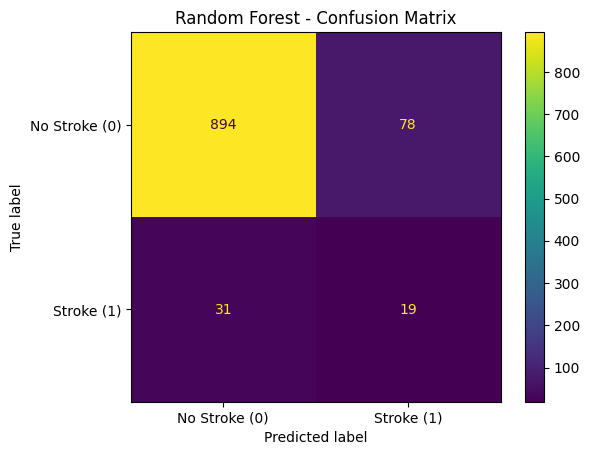

,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.8933,0.1959,0.38,0.2585


In [ ]:
# Task 4: Evaluate the tuned Random Forest model

# 1. Predict using the best Random Forest model
rf_predictions = best_rf.predict(X_test)

# 2. Calculate evaluation metrics
rf_results = {
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_test, rf_predictions),
    'Precision': precision_score(
        y_test, rf_predictions, zero_division=0
    ),
    'Recall': recall_score(
        y_test, rf_predictions, zero_division=0
    ),
    'F1-score': f1_score(
        y_test, rf_predictions, zero_division=0
    )
}

# 3. Display evaluation metrics
print("Random Forest Evaluation")
print("------------------------")
print(f"Accuracy:  {rf_results['Accuracy']:.4f}")
print(f"Precision: {rf_results['Precision']:.4f}")
print(f"Recall:    {rf_results['Recall']:.4f}")
print(f"F1-score:  {rf_results['F1-score']:.4f}")

# 4. Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

# 5. Display confusion matrix
cm = confusion_matrix(y_test, rf_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Stroke (0)', 'Stroke (1)']
).plot()

plt.title('Random Forest - Confusion Matrix')
plt.show()

# 6. Store results in a DataFrame
rf_results_df = pd.DataFrame([rf_results])
display(rf_results_df.round(4))

### Evaluation - Random Forest:

The tuned Random Forest was evaluated using the test dataset, consisting of 1022 records. Its performance was measured using accuracy, percision, recall, and F1-score. A confusion matric and classification report were also generated to examine the model's predictions.

The model achieved an accuracy of 0.8933, a precision of 0.1959, a recall of 0.3800, and an F1-score of 0.2585. Although the model achieved relatively high overall accuracy, its precision and F1-score were considerably lower, indicating limitations in identifying stroke cases accurately.

The confusion matrix showed 894 true negatives and 19 true positives. However, the model produced 78 false positives and 31 false negatives. Among the 50 actual stroke cases in the test dataset, the model correctly identified only 19 cases, corresponding to a recall of 38%. This means that 31 actual stroke cases were incorrectly classified as no stroke.

These results suggest that the model performs better at identifying the majority class (no stroke) than the minority class (stroke). The class imbalance in the dataset may contribute to this difference. Therefore, accuracy alone is insufficient to asses the model's effectiveness, and recall and F1-score are important considerations for stroke prediction. Overall, the tuned Random Forest model achieved relatively high accuracy but showed limited performance in identifying stroke cases.


# Task 5: Comparison

### Discuss the comparison